Bagging Accuracy: 96.66666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



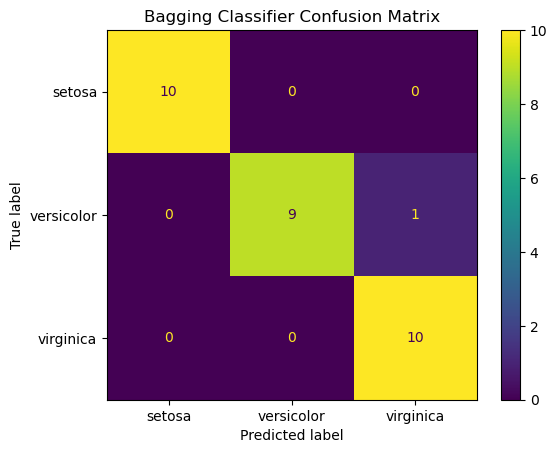

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create base model
dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Create Bagging Classifier
bagging_model = BaggingClassifier(
    estimator=dt,
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train model
bagging_model.fit(X_train, y_train)

# Predictions
y_pred = bagging_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Bagging Accuracy:", accuracy * 100)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()
plt.title("Bagging Classifier Confusion Matrix")
plt.show()

In [2]:
# Bootstrap Sampling: Randomly select observations with replacement.
# Each bootstrap sample has the same size as the original dataset.

import numpy as np

X = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

np.random.seed(42)

for i in range(3):
    indices = np.random.choice(len(X), size=len(X), replace=True)
    sample = X[indices]

    print(f"Bootstrap Sample {i+1}: {sample}")

Bootstrap Sample 1: [ 70  40  80  50  70 100  30  70  80  50]
Bootstrap Sample 2: [40 80 80 30 60 50 20 80 60 20]
Bootstrap Sample 3: [ 50  10 100  60  90  10 100  30  70  40]


In [3]:
# Bagging Classifier: Train multiple Decision Trees on different bootstrap samples.
# Final classification is based on majority voting.

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9666666666666667


In [4]:
# OOB Evaluation: Evaluate training observations using trees that did not train on them.
# It provides an internal performance estimate without a separate validation set.

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("OOB Score:", model.oob_score_)
print("Test Accuracy:", model.score(X_test, y_test))

OOB Score: 0.95
Test Accuracy: 0.9666666666666667


In [5]:
# Bagging Regressor: Train multiple regression models on bootstrap samples.
# Final prediction is calculated by averaging individual model predictions.

from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

data = load_diabetes()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=5),
    n_estimators=100,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

RMSE: 53.75498822994764
R2 Score: 0.45460249219723614


In [6]:
# Bagging Setup: Load Iris dataset, split into training and testing data.
# Prepare a Decision Tree base estimator for Bagging experiments.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (120, 4)
Testing shape: (30, 4)


Estimators: 1, Accuracy: 0.9667


Exception ignored in: <function ResourceTracker.__del__ at 0x1056e9bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10855dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Estimators: 5, Accuracy: 0.9667


Exception ignored in: <function ResourceTracker.__del__ at 0x1049cdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Estimators: 10, Accuracy: 0.9667
Estimators: 20, Accuracy: 0.9667
Estimators: 50, Accuracy: 0.9667
Estimators: 100, Accuracy: 0.9667
Estimators: 200, Accuracy: 0.9667


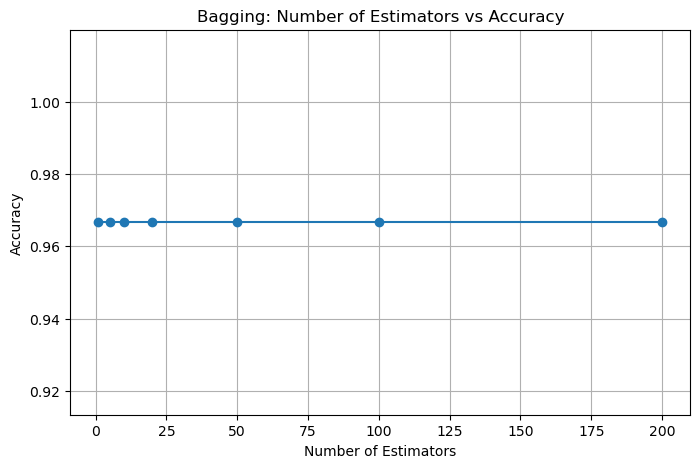

In [7]:
# N Estimators: Compare Bagging performance with different numbers of trees.
# More estimators can stabilize predictions but increase computation time.

estimators = [1, 5, 10, 20, 50, 100, 200]

results = []

for n in estimators:

    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Estimators: {n}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(estimators, results, marker="o")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("Bagging: Number of Estimators vs Accuracy")
plt.grid()
plt.show()

Max Samples: 0.3, Accuracy: 0.9667
Max Samples: 0.5, Accuracy: 0.9667
Max Samples: 0.7, Accuracy: 0.9667
Max Samples: 0.8, Accuracy: 0.9667
Max Samples: 1.0, Accuracy: 0.9667


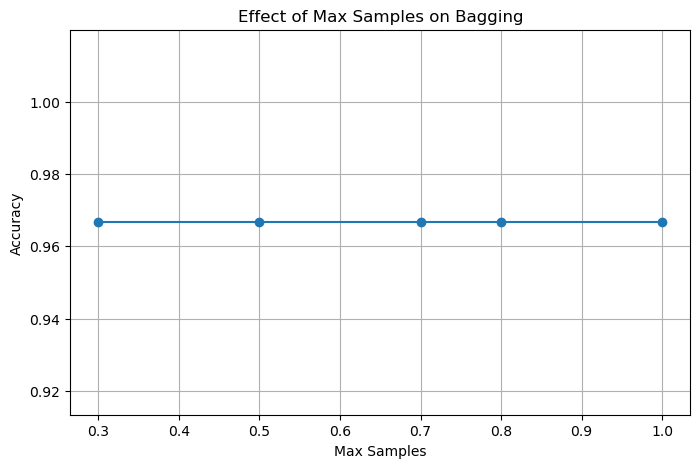

In [8]:
# Max Samples: Control how many training observations each estimator receives.
# Fractional values select a proportion of the training dataset.

sample_values = [0.3, 0.5, 0.7, 0.8, 1.0]

results = []

for sample in sample_values:

    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        max_samples=sample,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Max Samples: {sample}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(sample_values, results, marker="o")
plt.xlabel("Max Samples")
plt.ylabel("Accuracy")
plt.title("Effect of Max Samples on Bagging")
plt.grid()
plt.show()

Max Features: 0.25, Accuracy: 0.9000
Max Features: 0.5, Accuracy: 0.9333
Max Features: 0.75, Accuracy: 0.9333
Max Features: 1.0, Accuracy: 0.9667


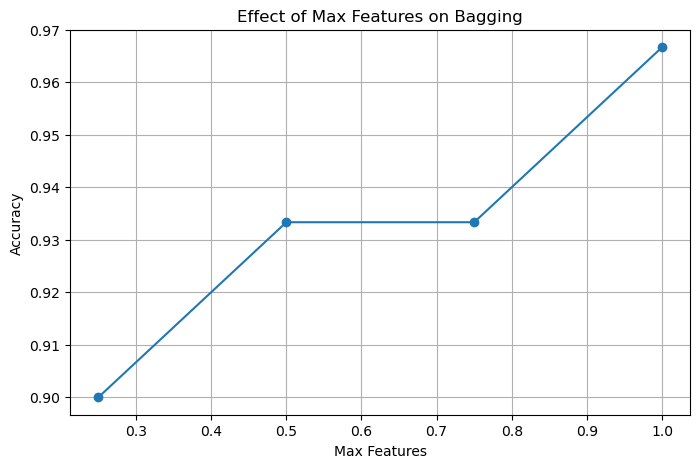

In [9]:
# Max Features: Control how many input features each estimator receives.
# Feature sampling can introduce additional diversity among base estimators.

feature_values = [0.25, 0.5, 0.75, 1.0]

results = []

for feature in feature_values:

    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        max_features=feature,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Max Features: {feature}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(feature_values, results, marker="o")
plt.xlabel("Max Features")
plt.ylabel("Accuracy")
plt.title("Effect of Max Features on Bagging")
plt.grid()
plt.show()

Decision Tree: 0.9667
Logistic Regression: 0.9667
KNN: 1.0000
SVM: 0.9667


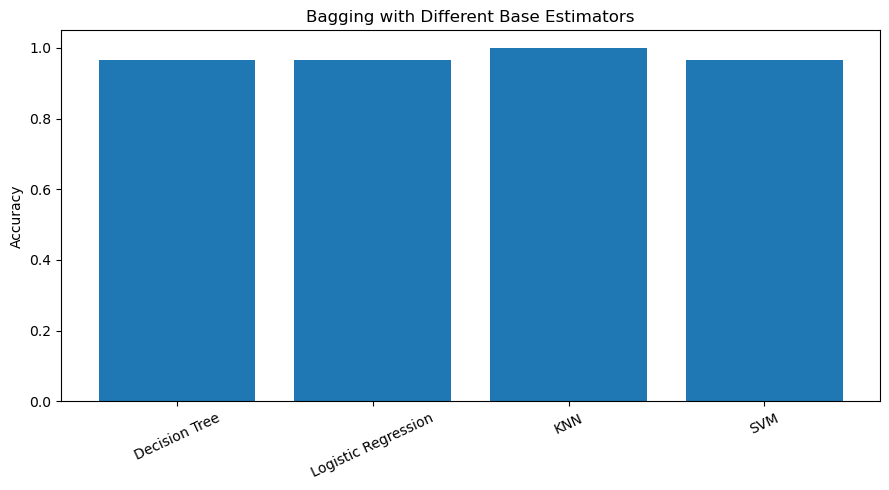

In [10]:
# Base Estimator Comparison: Compare different algorithms inside Bagging.
# Each algorithm is trained using the same bootstrap aggregation technique.

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

base_models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC()
}

results = {}

for name, estimator in base_models.items():

    model = BaggingClassifier(
        estimator=estimator,
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results[name] = accuracy_score(y_test, y_pred)

for name, score in results.items():
    print(f"{name}: {score:.4f}")

plt.figure(figsize=(9, 5))
plt.bar(results.keys(), results.values())
plt.ylabel("Accuracy")
plt.title("Bagging with Different Base Estimators")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [11]:
# Model Comparison: Compare one Decision Tree against an ensemble of Decision Trees.
# Both models use the same training and testing datasets.

dt = DecisionTreeClassifier(random_state=42)

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

dt.fit(X_train, y_train)
bagging.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
bagging_pred = bagging.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
bagging_accuracy = accuracy_score(y_test, bagging_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Bagging Accuracy:", bagging_accuracy)

comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Bagging"],
    "Accuracy": [dt_accuracy, bagging_accuracy]
})

print(comparison)

Decision Tree Accuracy: 0.9333333333333333
Bagging Accuracy: 0.9666666666666667
           Model  Accuracy
0  Decision Tree  0.933333
1        Bagging  0.966667


In [12]:
# GridSearchCV: Find the best Bagging hyperparameters using 5-fold cross-validation.
# Select the best configuration based on average validation accuracy.

from sklearn.model_selection import GridSearchCV

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_samples": [0.5, 0.8, 1.0],
    "max_features": [0.5, 1.0],
    "estimator__max_depth": [2, 3, 5, None],
    "estimator__min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=bagging,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters:
{'estimator__max_depth': 2, 'estimator__min_samples_leaf': 4, 'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 100}

Best Cross Validation Accuracy:
0.9666666666666668

Test Accuracy:
0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [13]:
# RandomizedSearchCV: Test a limited number of randomly selected hyperparameter combinations.
# Useful when GridSearchCV becomes expensive because of a large search space.

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42,
    n_jobs=1
)

param_distributions = {
    "n_estimators": randint(50, 251),
    "max_samples": uniform(0.4, 0.6),
    "max_features": uniform(0.4, 0.6),
    "estimator__max_depth": [2, 3, 4, 5, None],
    "estimator__min_samples_leaf": randint(1, 6)
}

random_search = RandomizedSearchCV(
    estimator=bagging,
    param_distributions=param_distributions,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(random_search.best_score_)

print("\nTest Accuracy:")
print(random_search.best_estimator_.score(X_test, y_test))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'estimator__max_depth': 5, 'estimator__min_samples_leaf': 4, 'max_features': np.float64(0.619817105976215), 'max_samples': np.float64(0.6736419905302216), 'n_estimators': 224}

Best CV Accuracy:
0.9666666666666668

Test Accuracy:
0.9333333333333333


Exception ignored in: <function ResourceTracker.__del__ at 0x109295bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106d19bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10645dbc0>
Traceback (most recent call last